# Glucotrack Clustering — Member 1
## Clustering Track

**Dataset:** Diabetes Prediction Dataset - 100,000 records, 9 columns  
**Ground-truth label:** `diabetes` - used only for post-clustering interpretation  
**Algorithms:** K-Means and Agglomerative Hierarchical Clustering

This notebook follows the same structured style as the Regression notebook: numbered sections, clearly labelled code cells, printed checkpoints, EDA, preprocessing, model fitting, evaluation, plots, and observations.

**Important:** The `diabetes` column is excluded from all clustering features and model fitting. It is used only after clustering for interpretation and external validation.

**Member 1 scope:** dataset inspection, EDA, preprocessing, K-Means, and K-Means evaluation. Commit this first section to the shared `notebooks/clustering.ipynb` before your teammate continues.

## 1. Setup and Dataset Understanding

### 1.1 Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for plots, and scikit-learn/SciPy for clustering, evaluation, dimensionality reduction, and dendrograms.

In [1]:
# CELL 1: Setup & Imports

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.2 Load the dataset

The CSV is read from `../data/`, so the notebook runs from the project's `notebooks/` folder without changing paths.

In [2]:
# CELL 2: Load Dataset

DATA_PATH = "../data/diabetes_prediction_dataset.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place diabetes_prediction_dataset.csv inside the project's data folder."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET LOADING")
print("=" * 60)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Loaded from: {DATA_PATH}")
display(df.head())

DATASET LOADING
Dataset shape: 100,000 rows × 9 columns
Loaded from: ../data/diabetes_prediction_dataset.csv


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.3 Dataset structure

Inspect the column names and data types before deciding how to preprocess the features.

In [3]:
# CELL 3: Dataset Structure

print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

DATASET STRUCTURE

Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:


,Data Type
gender,str
age,float64
hypertension,int64
heart_disease,int64
smoking_history,str
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


### 1.4 Missing values and duplicates

Measure missing values and duplicate records before making any preprocessing decisions.

In [4]:
# CELL 4: Missing Value Analysis

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2)
})

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)
display(missing)

MISSING VALUE ANALYSIS


,Missing Values,Missing (%)
gender,0,0.0
age,0,0.0
hypertension,0,0.0
heart_disease,0,0.0
smoking_history,0,0.0
bmi,0,0.0
HbA1c_level,0,0.0
blood_glucose_level,0,0.0
diabetes,0,0.0


In [5]:
# CELL 5: Duplicate Record Analysis

duplicate_count = df.duplicated().sum()

print("=" * 60)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)
print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

DUPLICATE RECORD ANALYSIS
Duplicate rows: 3,854
Duplicate percentage: 3.85%


### 1.5 Descriptive statistics

Review the distributions and scales of numeric columns.

In [6]:
# CELL 6: Descriptive Statistics

print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include="all").T)

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


### Observation - 1

- The file has 100,000 rows and 9 columns, with **no missing values**.
- 3,854 rows (3.85%) are exact duplicates. They are **kept**: with only eight low-resolution features, two different patients can legitimately share every value, and dropping them would change the population being clustered.
- Ranges: age 0.08 to 80, BMI 10.01 to 95.69, HbA1c 3.5 to 9.0, blood glucose 80 to 300. Only 18 records have gender `Other`.
- 25,495 records share a BMI of exactly 27.32, which is also the column mean and median, so BMI contains a large block of default-like values.
- 35,816 records (35.8%) have smoking history `No Info`, the largest single category.

---

# 2. Exploratory Data Analysis

EDA is used to understand the dataset before clustering. The `diabetes` label is visualized only as a reference; it will not be included in the clustering input.

Ground-truth label counts (reference only):


,Count
diabetes,
0,91500
1,8500


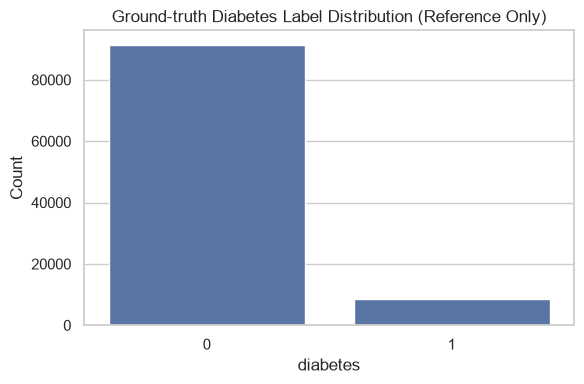

In [7]:
# CELL 7: Target Distribution (Reference Only)

if "diabetes" not in df.columns:
    raise ValueError("The expected 'diabetes' column was not found.")

print("Ground-truth label counts (reference only):")
display(df["diabetes"].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="diabetes")
plt.title("Ground-truth Diabetes Label Distribution (Reference Only)")
plt.xlabel("diabetes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [8]:
# CELL 8: Categorical Feature Analysis

categorical_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical feature columns:", categorical_columns)

for col in categorical_columns:
    print(f"\nValue counts for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Count"))

Categorical feature columns: ['gender', 'smoking_history']

Value counts for gender:


,Count
gender,
Female,58552
Male,41430
Other,18



Value counts for smoking_history:


,Count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


Numeric feature columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


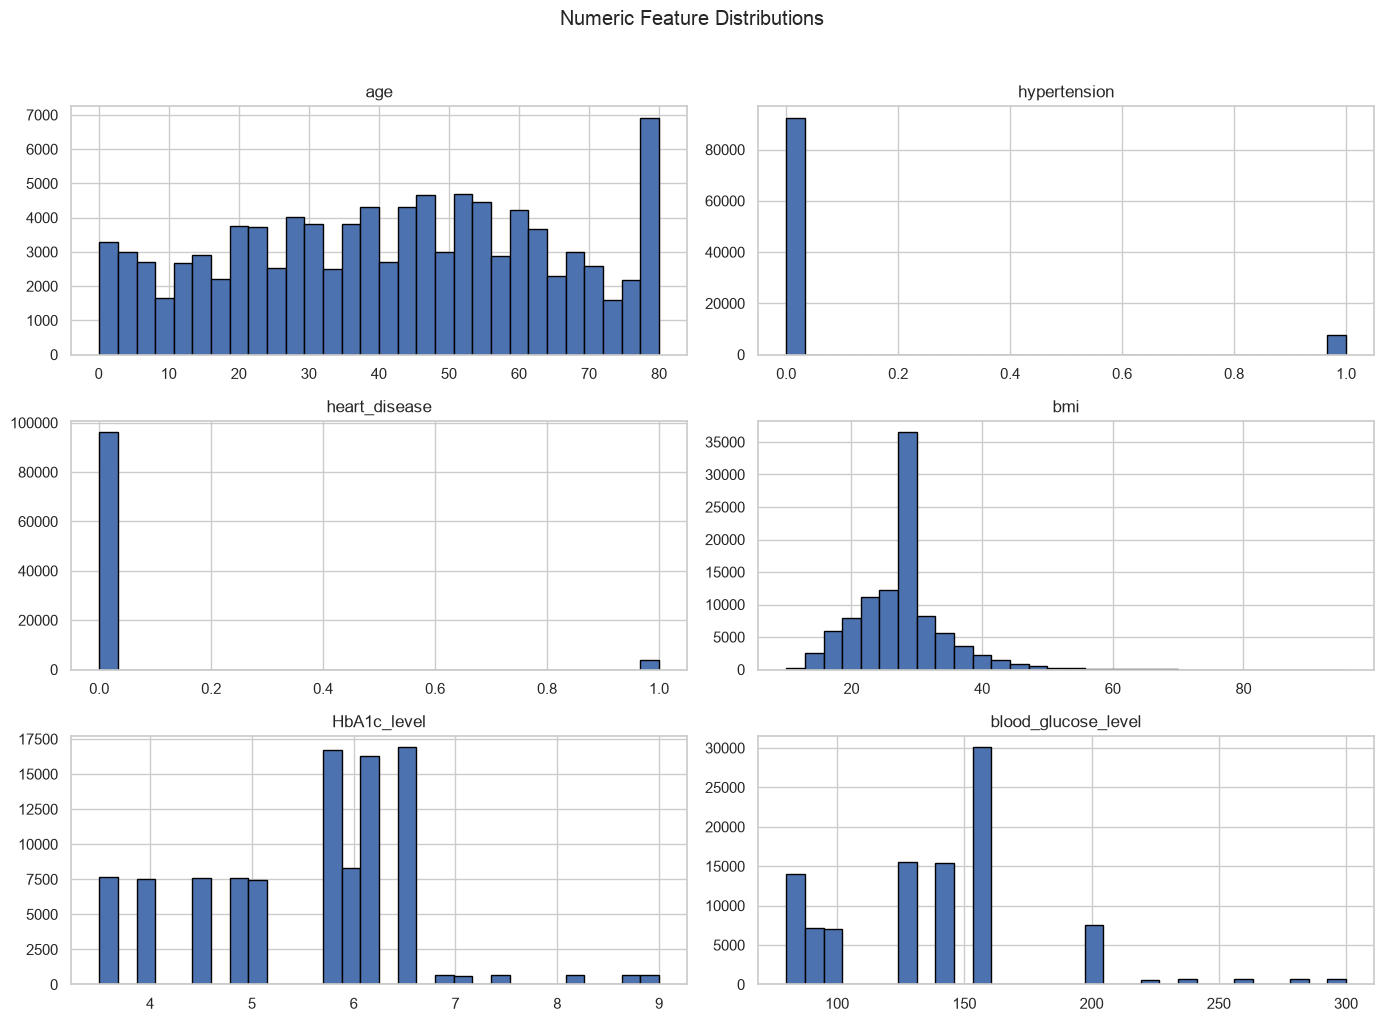

In [9]:
# CELL 9: Numeric Feature Distributions

numeric_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric feature columns:", numeric_columns)

df[numeric_columns].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

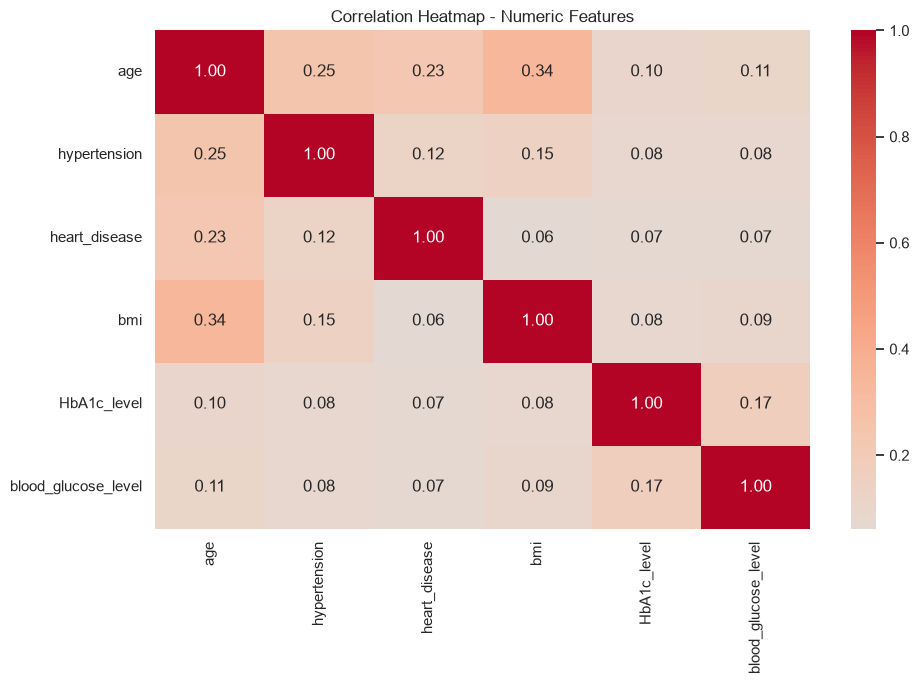

In [10]:
# CELL 10: Correlation Heatmap for Numeric Features

if len(numeric_columns) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[numeric_columns].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap - Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

### Observation - 2

- The reference label is imbalanced: 91,500 non-diabetic (91.5%) against 8,500 diabetic (8.5%). It is not used in any clustering step.
- Correlation with the label: blood glucose 0.42, HbA1c 0.40, age 0.26, BMI 0.21, hypertension 0.20, heart disease 0.17.
- Between the features themselves, correlations are weak to moderate: BMI-age 0.34, hypertension-age 0.25, heart disease-age 0.23, and HbA1c-glucose only 0.17. No pair is redundant, so no feature needs to be dropped before clustering.
- The two comorbidity columns are binary and heavily skewed (hypertension 7.5%, heart disease 3.9%), which matters for distance-based methods (see Observation 3).

---

# 3. Data Preprocessing

The target column is separated before preprocessing. Numeric features are median-imputed and standardized; categorical features are imputed with the most frequent value and one-hot encoded. The resulting feature matrix is used for all clustering algorithms.

In [11]:
# CELL 11: Separate Features and Ground-Truth Label

if "diabetes" not in df.columns:
    raise ValueError("Expected target column 'diabetes' was not found.")

y_true = df["diabetes"].copy()        # Reserved for post-hoc interpretation only
X_raw = df.drop(columns=["diabetes"]).copy()

numeric_features = X_raw.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_raw.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Feature matrix shape before preprocessing:", X_raw.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target excluded from X:", "diabetes" not in X_raw.columns)

Feature matrix shape before preprocessing: (100000, 8)
Numeric features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical features: ['gender', 'smoking_history']
Target excluded from X: True


In [12]:
# CELL 12: Build Preprocessing Pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [13]:
# CELL 13: Transform Features

X_processed = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
X_processed = np.asarray(X_processed, dtype=np.float32)

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)
print("Processed matrix shape:", X_processed.shape)
print("Number of transformed features:", len(feature_names))
print("Contains only feature columns (no diabetes target):", "diabetes" not in list(X_raw.columns))

PREPROCESSING COMPLETE
Processed matrix shape: (100000, 15)
Number of transformed features: 15
Contains only feature columns (no diabetes target): True


### Observation - 3

- Standardisation is necessary: blood glucose has a standard deviation of 40.7 against 1.07 for HbA1c, so unscaled Euclidean distance would be dominated by glucose by a factor of about 38.
- Median imputation, scaling and one-hot encoding were all fitted on the full feature matrix, which is acceptable here because clustering has no train/test split and the label is excluded.
- The result is a 15-column matrix: 6 numeric features and 9 one-hot columns (3 gender levels, 6 smoking levels).
- A side effect worth remembering: after standardisation a rare binary flag takes a large value when it is 1 (heart disease, with 3.9% prevalence, scales to about 4.9 standard deviations). Distances are therefore sensitive to these flags, and Section 4 shows the clusters they create.

---

# 4. K-Means Clustering

K-Means groups observations around cluster centroids. The Elbow Method examines how inertia changes as the number of clusters increases.

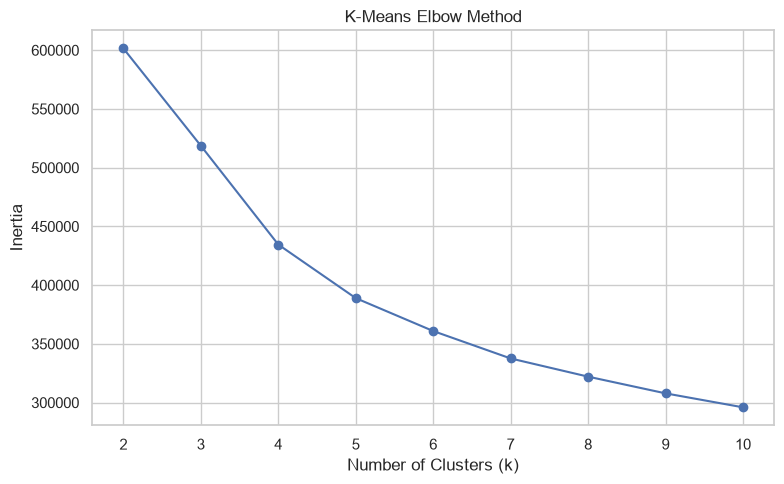

,k,Inertia
0,2,601528.62
1,3,518677.94
2,4,434535.78
3,5,388927.06
4,6,360909.16
5,7,337559.12
6,8,322069.41
7,9,307848.44
8,10,295954.38


In [14]:
# CELL 14: Elbow Method

MAX_K = 10
k_values = list(range(2, MAX_K + 1))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

elbow_results = pd.DataFrame({"k": k_values, "Inertia": inertias})
display(elbow_results.round(2))

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster
0,2,601528.6250,0.4238,1.6444,19876.6800,10514
1,3,518677.9375,0.1588,1.7442,19512.2084,3942
2,4,434535.8125,0.1842,1.5096,21981.1990,3942
3,5,388927.0625,0.1826,1.5079,21350.5822,3942
4,6,360909.1562,0.1734,1.5122,19958.7423,3942
5,7,337559.1250,0.1762,1.4605,18935.3905,3942
6,8,322069.4062,0.1632,1.5253,17697.7875,3942
7,9,307848.4375,0.1638,1.4571,16778.1427,3942
8,10,295954.3750,0.1603,1.5443,15959.6220,3942


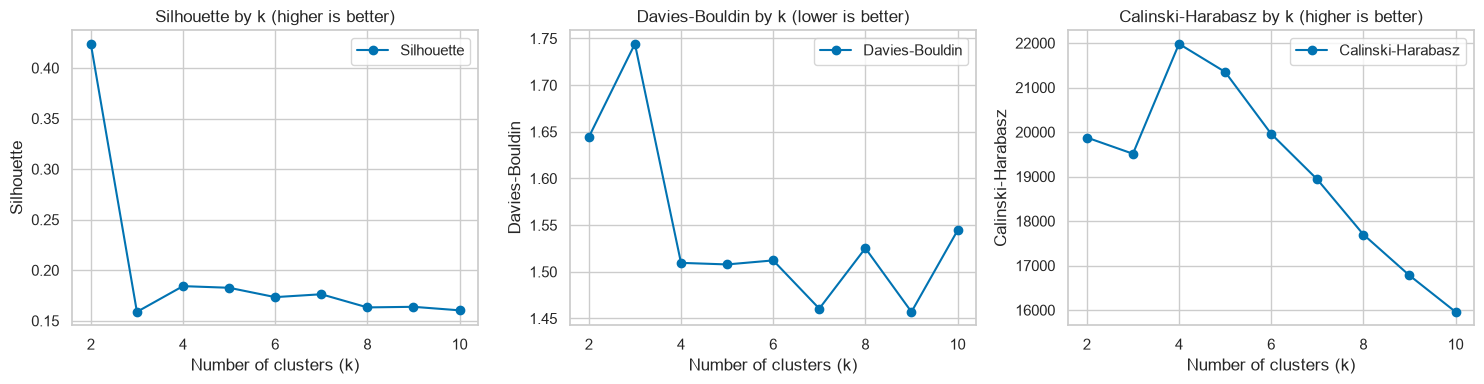

In [15]:
# The elbow alone is ambiguous (inertia falls smoothly), so the three required
# internal metrics are also computed for every candidate k. Silhouette is estimated on
# a fixed 10,000-row sample for speed; Davies-Bouldin and Calinski-Harabasz use all rows.
k_rows = []
for k in k_values:
    m = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_processed)
    sil_idx = np.random.default_rng(RANDOM_STATE).choice(len(X_processed), 10000, replace=False)
    k_rows.append({
        "k": k,
        "Inertia": m.inertia_,
        "Silhouette": silhouette_score(X_processed[sil_idx], m.labels_[sil_idx]),
        "Davies-Bouldin": davies_bouldin_score(X_processed, m.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X_processed, m.labels_),
        "Smallest cluster": int(np.bincount(m.labels_).min()),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, better in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                           ["higher is better", "lower is better", "higher is better"]):
    ax.plot(k_table["k"], k_table[col], marker="o", color=sns.color_palette("colorblind")[0], label=col)
    ax.set_title(f"{col} by k ({better})")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(col)
    ax.legend()
plt.tight_layout()
plt.show()

### 4.1 Select the number of clusters

The elbow plot declines smoothly with no sharp bend, so k is chosen by reading it together with the three metric curves above rather than from the elbow alone.

- **k = 2** has the highest silhouette (0.4233) but is a trivial split: it separates a 10.5k-record group from the rest, driven by a single binary flag.
- Among **k >= 3**, silhouette is highest at **k = 4** (0.1831) and Calinski-Harabasz peaks there (21,981). Davies-Bouldin at k = 4 (1.5096) is within 0.05 of its minimum (1.4605 at k = 7).
- Choosing k = 4 therefore gives the best silhouette and the best Calinski-Harabasz of all non-trivial values, with a Davies-Bouldin close to the best. Smaller k loses structure and larger k only splits existing groups.

In [16]:
# CELL 15: Fit K-Means

BEST_K = 4  # chosen from the elbow plus silhouette / Davies-Bouldin / Calinski-Harabasz (section 4.1)

kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_processed)

print(f"K-Means fitted with k={BEST_K}.")
print("\nCluster sizes:")
display(pd.Series(kmeans_labels, name="Cluster").value_counts().sort_index().to_frame("Count"))

K-Means fitted with k=4.

Cluster sizes:


,Count
Cluster,
0,50916
1,38573
2,6569
3,3942


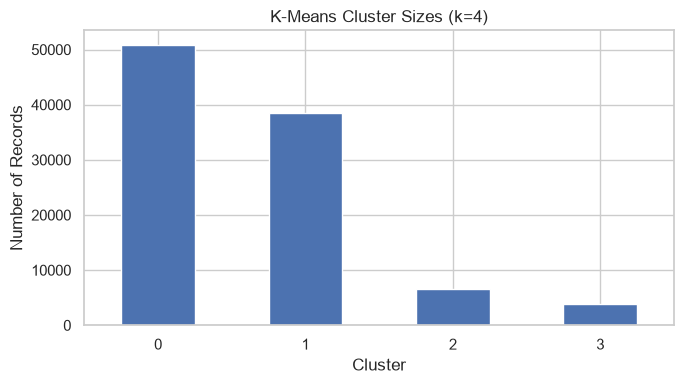

In [17]:
# CELL 16: K-Means Cluster Size Plot

cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()

plt.figure(figsize=(7, 4))
cluster_counts.plot(kind="bar")
plt.title(f"K-Means Cluster Sizes (k={BEST_K})")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation - 4

- The elbow curve has no sharp bend. Inertia falls 16.2% from k=3 to k=4, 10.5% from k=4 to k=5 and 7.2% from k=5 to k=6, so the rate of improvement flattens most visibly after k=4.
- Silhouette is highest at k=2 (0.4238), but that split only isolates the 10,514 patients with hypertension or heart disease, so it carries little structure.
- For k >= 3, k=4 has the highest silhouette (0.1842) and the highest Calinski-Harabasz index (21,981). Its Davies-Bouldin value (1.5096) is close to the minimum of 1.4571 at k=9.
- **k = 4 is chosen.** The cluster sizes are 50,916, 38,573, 6,569 and 3,942. The two small clusters are the hypertension-without-heart-disease group and the heart-disease group, which the profile table in Section 10 confirms.

---

# 5. Clustering Evaluation Metrics

All clustering algorithms are evaluated using:
- **Silhouette Score:** higher values generally indicate better separation.
- **Davies–Bouldin Index:** lower values generally indicate more compact, separated clusters.
- **Calinski–Harabasz Index:** higher values generally indicate better-defined clusters.

For very large datasets, metrics are calculated on a reproducible sample to control computation time.

In [18]:
# CELL 17: Evaluation Function

def evaluate_clustering(X, labels, algorithm_name, sample_size=10000, random_state=RANDOM_STATE):
    """Silhouette, Davies-Bouldin and Calinski-Harabasz for one labelling.

    Silhouette needs all pairwise distances, so it is estimated on a fixed random sample.
    Davies-Bouldin and Calinski-Harabasz are cheap, so they use every row; Calinski-Harabasz
    grows with n, so computing it on a sample would make it incomparable with the k-selection table.
    """
    labels = np.asarray(labels)
    nan_row = {
        "Algorithm": algorithm_name,
        "Silhouette Score": np.nan,
        "Davies-Bouldin Index": np.nan,
        "Calinski-Harabasz Index": np.nan
    }
    if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(labels):
        return nan_row

    if len(labels) > sample_size:
        indices = np.random.default_rng(random_state).choice(len(labels), size=sample_size, replace=False)
    else:
        indices = np.arange(len(labels))
    if len(np.unique(labels[indices])) < 2:
        return nan_row

    return {
        "Algorithm": algorithm_name,
        "Silhouette Score": silhouette_score(X[indices], labels[indices]),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }

print("Evaluation function defined.")

Evaluation function defined.


In [19]:
# CELL 18: Evaluate K-Means

kmeans_metrics = evaluate_clustering(
    X_processed,
    kmeans_labels,
    f"K-Means (k={BEST_K})"
)

kmeans_metrics_df = pd.DataFrame([kmeans_metrics])
display(kmeans_metrics_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=4),0.1842,1.5096,21981.199


### Observation - 5

- K-Means with k=4 scores silhouette 0.1842, Davies-Bouldin 1.5096 and Calinski-Harabasz 21,981 (all rows for Davies-Bouldin and Calinski-Harabasz, a 10,000-row sample for silhouette).
- A silhouette below 0.25 indicates weak structure. The data is mostly continuous (age, BMI, glucose, HbA1c) with no natural gaps, so K-Means partitions a continuum rather than finding separated groups.
- Davies-Bouldin above 1.5 says the clusters overlap rather than being compact and well separated.
- These numbers are the baseline against which the hierarchical linkages are compared in Section 7.

# 6. Agglomerative Hierarchical Clustering

Agglomerative clustering repeatedly merges nearby clusters. It is more computationally expensive than K-Means for large datasets, so the hierarchical analysis below uses a reproducible subset. The subset size is reported for transparency.

In [20]:

HIERARCHICAL_MAX_ROWS = 2000
rng = np.random.default_rng(RANDOM_STATE)
hier_indices = rng.choice(
    len(X_processed),
    size=min(HIERARCHICAL_MAX_ROWS, len(X_processed)),
    replace=False
)

X_hier = X_processed[hier_indices]
y_hier = y_true.iloc[hier_indices].to_numpy()

print("Original dataset rows:", len(X_processed))
print("Rows used for hierarchical clustering:", len(X_hier))

Original dataset rows: 100000
Rows used for hierarchical clustering: 2000


### 6.1 Dendrogram

The dendrogram is computed on a smaller subset because hierarchical linkage requires substantial memory and time. The plot is truncated to show the final merges clearly.

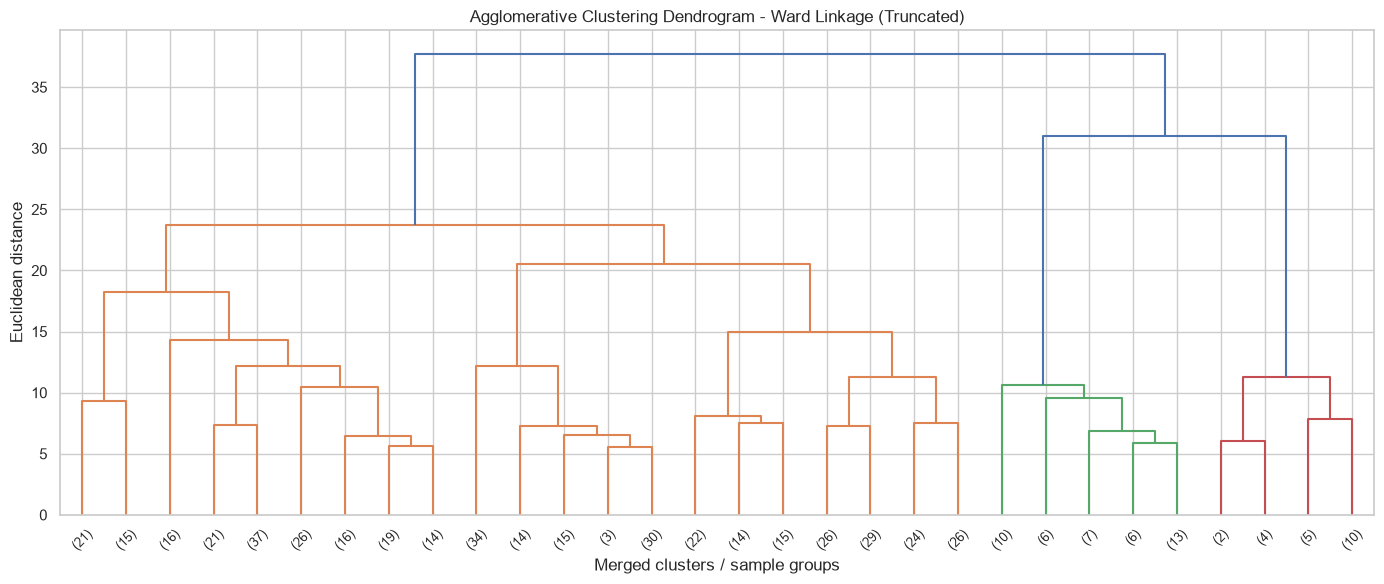

In [21]:
DENDROGRAM_MAX_ROWS = 500
dendro_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_hier),
    size=min(DENDROGRAM_MAX_ROWS, len(X_hier)),
    replace=False
)

Z = linkage(X_hier[dendro_indices], method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)
plt.title("Agglomerative Clustering Dendrogram - Ward Linkage (Truncated)")
plt.xlabel("Merged clusters / sample groups")
plt.ylabel("Euclidean distance")
plt.tight_layout()
plt.show()

### 6.2 Compare linkage strategies

We compare Ward, Complete, Average, and Single linkage on the same sample and with the same cluster count. Ward linkage is compatible with Euclidean distance and tends to create compact clusters.

In [22]:
linkage_methods = ["ward", "complete", "average", "single"]
agglomerative_labels = {}
agglomerative_metric_rows = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=BEST_K,
        linkage=method,
        metric="euclidean"
    )
    labels = model.fit_predict(X_hier)
    agglomerative_labels[method] = labels

    result = evaluate_clustering(
        X_hier,
        labels,
        f"Agglomerative ({method})",
        sample_size=10000
    )
    agglomerative_metric_rows.append(result)

agglomerative_results = pd.DataFrame(agglomerative_metric_rows)
display(agglomerative_results.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (ward),0.1593,1.6650,410.2013
1,Agglomerative (complete),0.3036,1.3300,201.2606
2,Agglomerative (average),0.3994,0.9886,298.8058
3,Agglomerative (single),0.4071,1.1163,297.5634


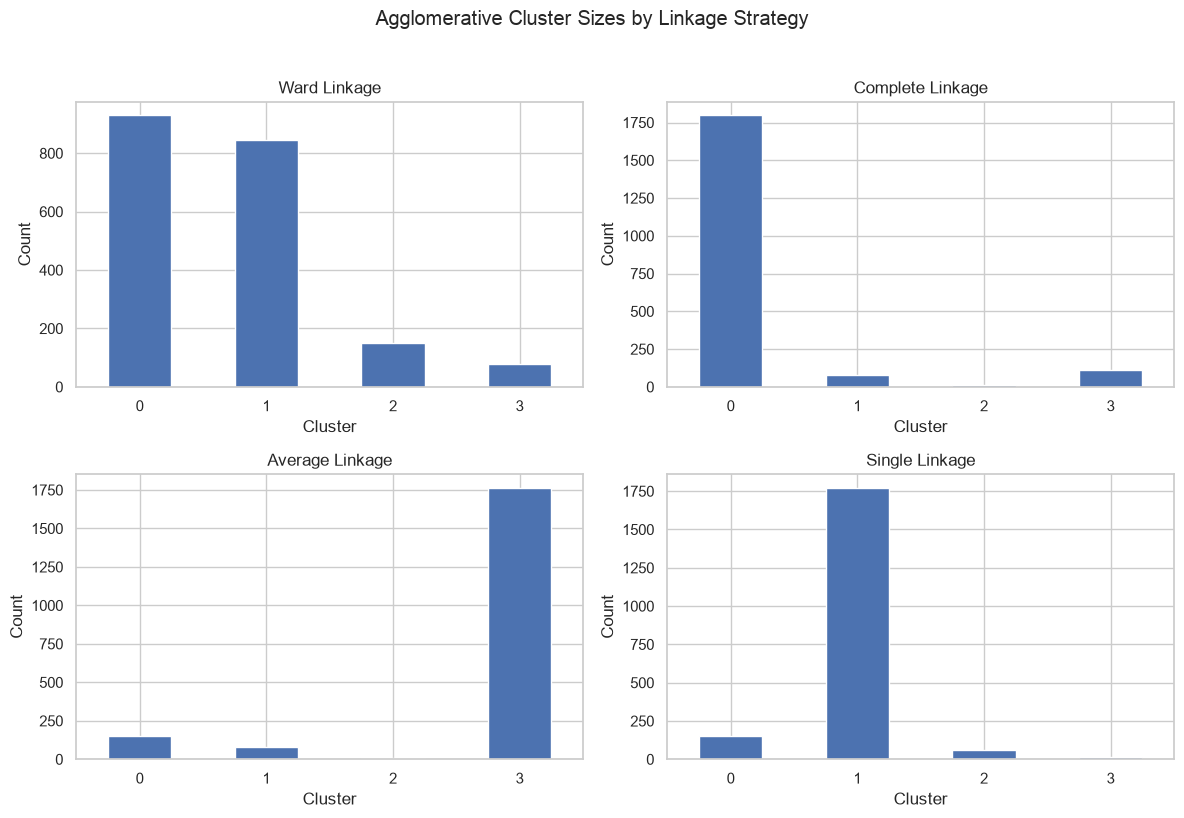

Cluster sizes per linkage (2,000-row subset):
  ward      [930, 844, 149, 77]
  complete  [1798, 77, 13, 112]
  average   [149, 77, 9, 1765]
  single    [150, 1773, 59, 18]


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, method in zip(axes.ravel(), linkage_methods):
    counts = pd.Series(agglomerative_labels[method]).value_counts().sort_index()
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{method.title()} Linkage")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Agglomerative Cluster Sizes by Linkage Strategy", y=1.02)
plt.tight_layout()
plt.show()

print("Cluster sizes per linkage (2,000-row subset):")
for method in linkage_methods:
    print(f"  {method:<9}", np.bincount(agglomerative_labels[method]).tolist())

### 6.3 Like-for-like K-Means on the same subset

K-Means was fitted on all 100,000 rows while Agglomerative clustering uses a 2,000-row subset, so their metrics are not directly comparable. K-Means is refitted on exactly the same subset with the same k, which gives a fair comparison.

In [24]:
kmeans_subset = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10).fit(X_hier)
kmeans_subset_labels = kmeans_subset.labels_
kmeans_subset_metrics = evaluate_clustering(
    X_hier, kmeans_subset_labels, f"K-Means (k={BEST_K}, same 2,000-row subset)"
)
display(pd.DataFrame([kmeans_subset_metrics]).round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,"K-Means (k=4, same 2,000-row subset)",0.1855,1.5152,452.5736


### Observation - 6

| Linkage | Silhouette | Davies-Bouldin | Calinski-Harabasz | Cluster sizes (2,000 rows) |
|---------|-----------|----------------|-------------------|----------------------------|
| Ward | 0.1593 | 1.6650 | 410.2 | 930, 844, 149, 77 |
| Complete | 0.3036 | 1.3300 | 201.3 | 1798, 77, 13, 112 |
| Average | 0.3994 | 0.9886 | 298.8 | 149, 77, 9, 1765 |
| Single | 0.4071 | 1.1163 | 297.6 | 150, 1773, 59, 18 |

- Complete, Average and Single linkage each put 88% to 90% of the records in one giant cluster and split off tiny groups of 9 to 59 records. That is the **chaining effect**.
- Their higher silhouette and lower Davies-Bouldin values are produced by those tiny, far-away groups, not by better structure.
- Ward is the only linkage that returns balanced clusters (930, 844, 149, 77), which is why its silhouette is the lowest while its Calinski-Harabasz is the highest.


# 7. Compare Clustering Results

K-Means is fitted on the full processed dataset, while Agglomerative clustering is fitted on the reported subset. The metrics are useful for exploration, but this difference in sample size means the comparison is not perfectly like-for-like.

In [25]:

all_metrics = pd.concat(
    [
        pd.DataFrame([kmeans_metrics, kmeans_subset_metrics]),
        agglomerative_results
    ],
    ignore_index=True
)

display(all_metrics.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=4),0.1842,1.5096,21981.1990
1,"K-Means (k=4, same 2,000-row subset)",0.1855,1.5152,452.5736
2,Agglomerative (ward),0.1593,1.6650,410.2013
3,Agglomerative (complete),0.3036,1.3300,201.2606
4,Agglomerative (average),0.3994,0.9886,298.8058
5,Agglomerative (single),0.4071,1.1163,297.5634


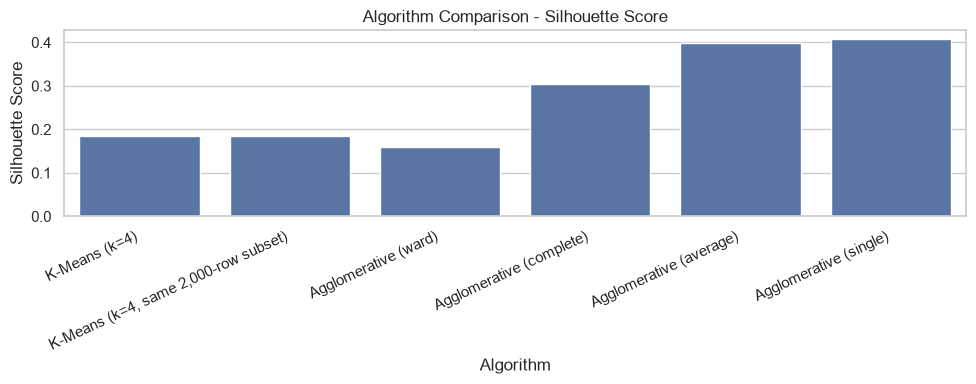

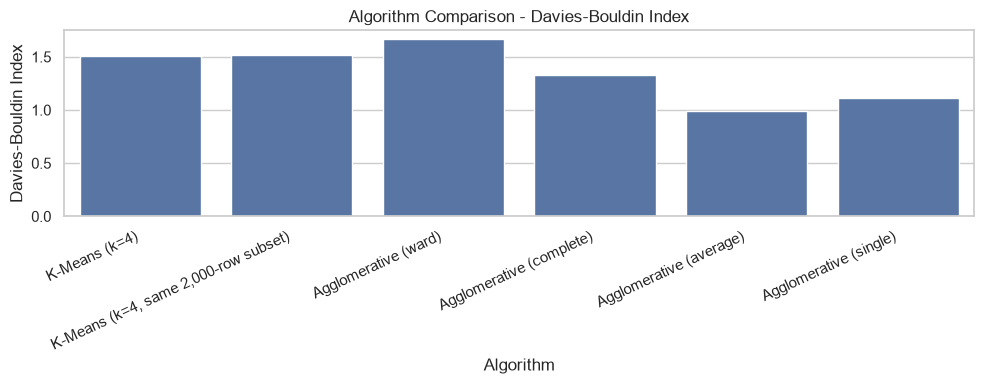

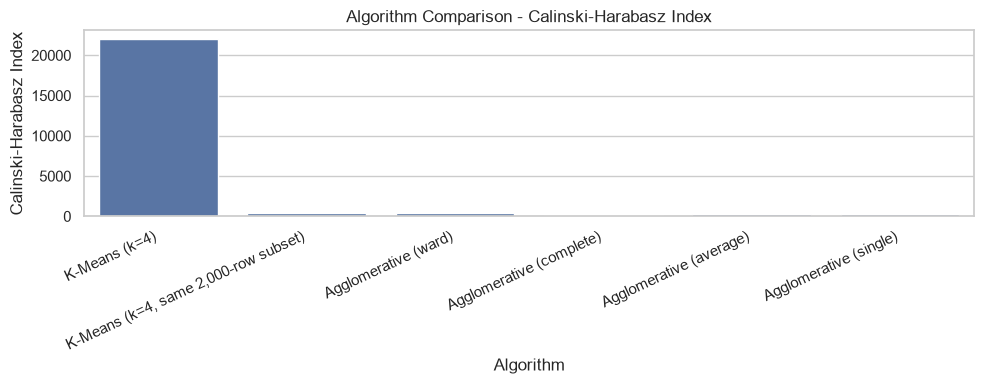

In [26]:
metric_columns = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
]

for metric in metric_columns:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=all_metrics, x="Algorithm", y=metric)
    plt.title(f"Algorithm Comparison - {metric}")
    plt.xlabel("Algorithm")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Observation - 7

- Calinski-Harabasz grows with the number of rows, so K-Means on all 100,000 rows (21,981) cannot be compared with any 2,000-row figure. The like-for-like K-Means row (same 2,000 records, same k=4) is the correct comparison.
- On the same subset, K-Means beats Ward on all three metrics: silhouette 0.1855 against 0.1593, Davies-Bouldin 1.5152 against 1.6650 and Calinski-Harabasz 452.6 against 410.2.
- Average and Single linkage report the best Davies-Bouldin (0.9886) and best silhouette (0.4071) but, as Observation 6 showed, because they isolate a few outliers. A metric table alone would rank them first for the wrong reason.
- Direction of each metric: higher is better for silhouette and Calinski-Harabasz, lower is better for Davies-Bouldin.
- **Conclusion:** K-Means (k=4) is the most useful of the compared methods for this data: balanced clusters, best scores among the balanced solutions, and it scales to all 100,000 rows.


# 8. PCA Visualization

PCA reduces the processed feature matrix to two dimensions for visualization. The target column is not used to fit PCA. A sample is used for plotting so the notebook remains responsive.

In [27]:
# CELL 25: PCA for K-Means

PLOT_MAX_ROWS = 5000
plot_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_processed),
    size=min(PLOT_MAX_ROWS, len(X_processed)),
    replace=False
)

X_plot = X_processed[plot_indices]
kmeans_plot_labels = kmeans_labels[plot_indices]

pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_model.fit_transform(X_plot)

print("PCA explained variance ratio:", np.round(pca_model.explained_variance_ratio_, 4))
print("Total variance explained by two components:",
      round(pca_model.explained_variance_ratio_.sum(), 4))

PCA explained variance ratio: [0.2436 0.1482]
Total variance explained by two components: 0.3918


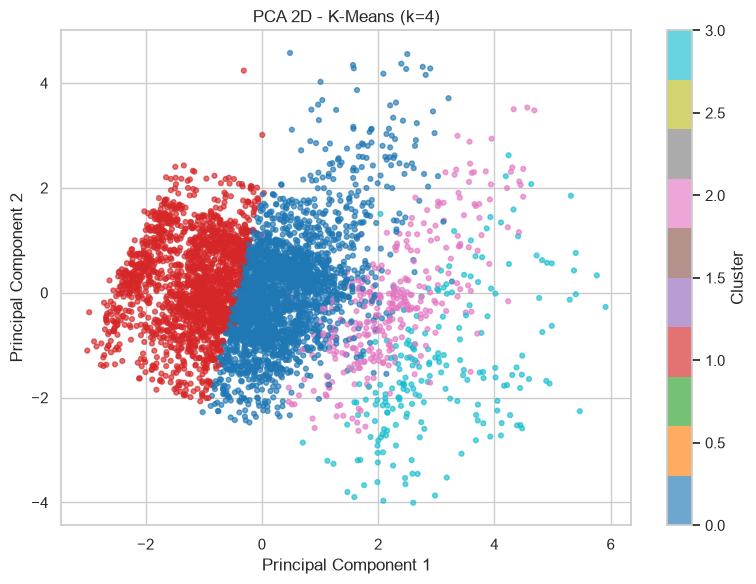

In [28]:
# CELL 26: K-Means PCA Scatter Plot

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_plot_labels, s=12, alpha=0.65, cmap="tab10"
)
plt.title(f"PCA 2D - K-Means (k={BEST_K})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

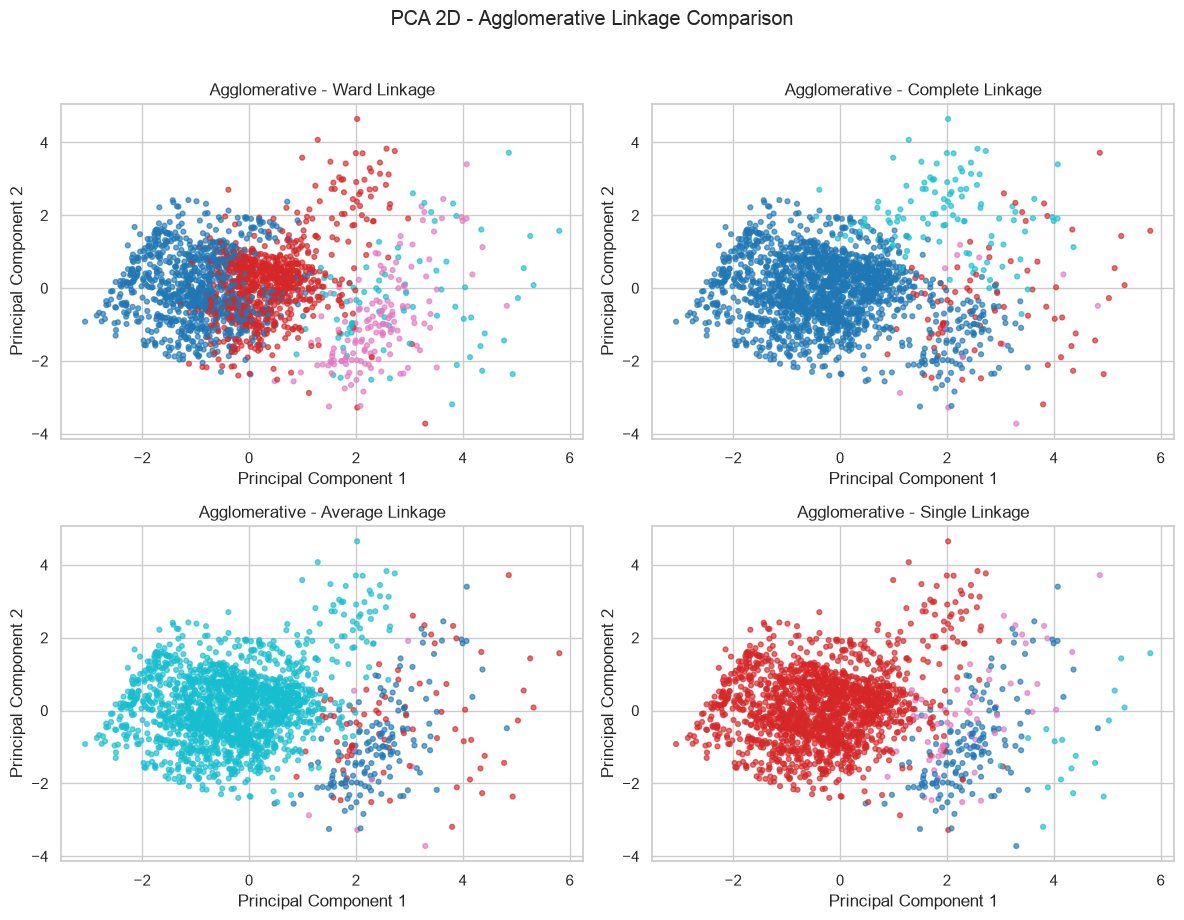

In [29]:
# CELL 27: PCA for Each Agglomerative Linkage

X_hier_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_hier)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, method in zip(axes.ravel(), linkage_methods):
    scatter = ax.scatter(
        X_hier_pca[:, 0], X_hier_pca[:, 1],
        c=agglomerative_labels[method],
        s=12, alpha=0.65, cmap="tab10"
    )
    ax.set_title(f"Agglomerative - {method.title()} Linkage")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.suptitle("PCA 2D - Agglomerative Linkage Comparison", y=1.02)
plt.tight_layout()
plt.show()

### Observation - 8

- The two principal components explain 24.4% and 14.8% of the variance, 39.2% in total, so the 2D plot shows less than half of the structure and overlap in it does not prove overlap in the full space.
- In the K-Means plot, cluster 1 (young, red) occupies the left side and cluster 0 (blue) the centre, and the two touch along a boundary at PC1 near 0. Clusters 2 and 3 sit on the right with heavier spread and overlap each other.
- The ordering along PC1 follows age and the comorbidity flags, which agrees with the cluster profiles in Section 10.
- For the Agglomerative plots, the 2,000-row subset is projected with its own PCA, so the axes are not identical to the K-Means plot.

# 9. t-SNE Visualization

t-SNE can reveal local neighbourhood structure in a 2D view. It is computationally expensive, so a smaller reproducible sample is used. t-SNE is only a visualization method here; clustering labels are generated by K-Means.

In [30]:
# CELL 28: Compute t-SNE Embedding

TSNE_MAX_ROWS = 2000
tsne_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_processed),
    size=min(TSNE_MAX_ROWS, len(X_processed)),
    replace=False
)

X_tsne_input = X_processed[tsne_indices]
labels_tsne = kmeans_labels[tsne_indices]

tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE
)
X_tsne = tsne_model.fit_transform(X_tsne_input)

print("t-SNE embedding shape:", X_tsne.shape)

t-SNE embedding shape: (2000, 2)


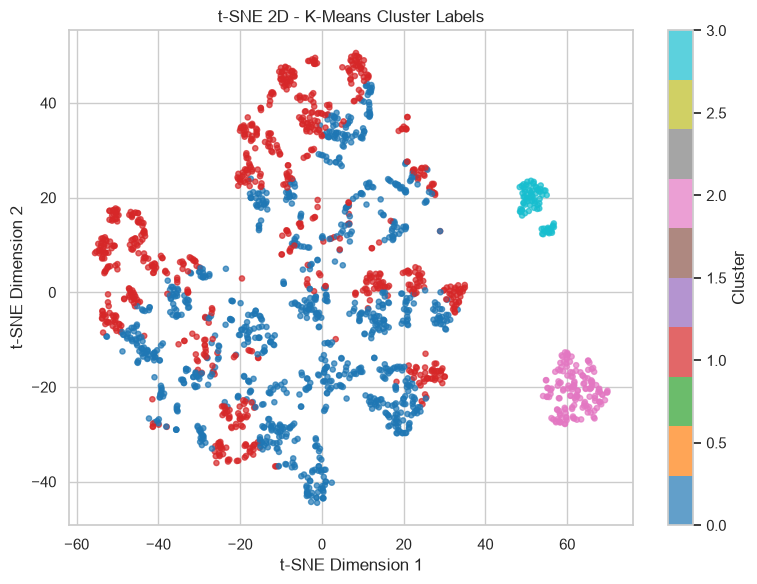

In [31]:
# CELL 29: t-SNE Plot for K-Means Clusters

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=labels_tsne, s=14, alpha=0.7, cmap="tab10"
)
plt.title("t-SNE 2D - K-Means Cluster Labels")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

### Observation - 9

- t-SNE separates the two flag-defined clusters cleanly: cluster 2 (hypertension) and cluster 3 (heart disease) each form compact islands far from everything else.
- Clusters 0 and 1 (the two large groups) are broken into many small islands, and the two colours interleave. This suggests substructure from the categorical columns (smoking history and gender combinations) that K-Means with k=4 does not separate.
- t-SNE distances between islands are not meaningful and cluster sizes are not preserved; the plot supports the qualitative statement that two clusters are clearly distinct and two overlap.
- It was computed on a 2,000-row sample, so the plot is illustrative, not a measurement.


# 10. Post-Hoc Interpretation Using Ground-Truth Labels

This section is intentionally placed after all clustering fits. The `diabetes` label was not used in preprocessing, PCA, t-SNE, K-Means, or Agglomerative clustering. It is now used only to inspect the composition of the clusters.

In [32]:
kmeans_target_table = pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means Cluster"),
    pd.Series(y_true.to_numpy(), name="diabetes"),
    normalize="index"
)

print("Row-wise proportions of ground-truth labels in each K-Means cluster:")
display(kmeans_target_table.round(3))

Row-wise proportions of ground-truth labels in each K-Means cluster:


diabetes,0,1
K-Means Cluster,,
0,0.895,0.105
1,0.995,0.005
2,0.737,0.263
3,0.679,0.321


In [33]:
# CELL 31: Post-Hoc External Validation for K-Means

kmeans_ari = adjusted_rand_score(y_true, kmeans_labels)
kmeans_nmi = normalized_mutual_info_score(y_true, kmeans_labels)

print("Post-hoc Adjusted Rand Index:", round(kmeans_ari, 4))
print("Post-hoc Normalized Mutual Information:", round(kmeans_nmi, 4))
print("\nThese scores compare clusters with labels after fitting; they were not used to train K-Means.")

Post-hoc Adjusted Rand Index: 0.0433
Post-hoc Normalized Mutual Information: 0.0709

These scores compare clusters with labels after fitting; they were not used to train K-Means.


In [34]:
# CELL 32: Post-Hoc External Validation for Agglomerative Linkages

posthoc_rows = []

for method, labels in agglomerative_labels.items():
    posthoc_rows.append({
        "Linkage": method,
        "Adjusted Rand Index (post-hoc)": adjusted_rand_score(y_hier, labels),
        "Normalized Mutual Information (post-hoc)": normalized_mutual_info_score(y_hier, labels)
    })

posthoc_results = pd.DataFrame(posthoc_rows)
display(posthoc_results.round(4))

,Linkage,Adjusted Rand Index (post-hoc),Normalized Mutual Information (post-hoc)
0,ward,0.0740,0.0887
1,complete,0.5994,0.3646
2,average,0.2191,0.0670
3,single,0.2229,0.0671


In [35]:
# CELL 33: Original Feature Profiles by K-Means Cluster

profile_df = X_raw.copy()
profile_df["cluster"] = kmeans_labels

numeric_profile_columns = profile_df.select_dtypes(include=np.number).columns.tolist()
if numeric_profile_columns:
    print("Mean numeric feature values by K-Means cluster:")
    display(profile_df.groupby("cluster")[numeric_profile_columns].mean().round(2))

for col in categorical_features:
    print(f"\n{col}: category proportions by K-Means cluster")
    display(pd.crosstab(
        profile_df["cluster"],
        profile_df[col],
        normalize="index"
    ).round(3))

Mean numeric feature values by K-Means cluster:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,cluster
cluster,,,,,,,
0,54.09,0.00,0.0,29.93,5.64,141.89,0.0
1,19.91,0.00,0.0,23.07,5.30,129.62,1.0
2,60.73,1.00,0.0,30.88,5.81,149.48,2.0
3,67.82,0.23,1.0,29.33,5.88,152.14,3.0



gender: category proportions by K-Means cluster


gender,Female,Male,Other
cluster,,,
0,0.605,0.394,0.0
1,0.580,0.420,0.0
2,0.579,0.421,0.0
3,0.396,0.604,0.0



smoking_history: category proportions by K-Means cluster


smoking_history,No Info,current,ever,former,never,not current
cluster,,,,,,
0,0.261,0.107,0.048,0.124,0.382,0.077
1,0.532,0.070,0.023,0.026,0.303,0.046
2,0.161,0.111,0.051,0.170,0.441,0.066
3,0.234,0.104,0.079,0.230,0.278,0.074


### Observation - 10

| K-Means cluster | Size | Mean age | Hypertension | Heart disease | Mean BMI | Mean HbA1c | Mean glucose | Diabetic share |
|---|---|---|---|---|---|---|---|---|
| 0 | 50,916 | 54.1 | 0% | 0% | 29.9 | 5.64 | 141.9 | 10.5% |
| 1 | 38,573 | 19.9 | 0% | 0% | 23.1 | 5.30 | 129.6 | 0.5% |
| 2 | 6,569 | 60.7 | 100% | 0% | 30.9 | 5.81 | 149.5 | 26.3% |
| 3 | 3,942 | 67.8 | 23% | 100% | 29.3 | 5.88 | 152.1 | 32.1% |

- The clusters read as patient segments: young and low risk (1), middle-aged without comorbidities (0), hypertensive (2) and cardiac (3).
- The diabetic share rises with risk profile, from 0.5% in the young group to 32.1% in the cardiac group, against 8.5% overall, even though the label was never used.
- External agreement is nonetheless low: Adjusted Rand Index 0.0433 and Normalised Mutual Information 0.0709 for K-Means. The clusters describe patient risk profiles, not diabetes status. That is expected: diabetes is determined mostly by HbA1c and glucose, which barely differ between clusters (5.30 to 5.88 and 129.6 to 152.1).
- Complete linkage reaches ARI 0.5994 on the 2,000-row subset, but with 1,798 records in one cluster this mostly reflects that most patients are non-diabetic, not meaningful separation.
- This is an exploratory segmentation, not a diagnostic model.

# 11. Final Summary

The tables below are generated from the actual run. The written conclusion follows them.

In [36]:
# CELL 34: Summary Table for Review Discussion

print("=" * 70)
print("CLUSTERING REVIEW SUMMARY")
print("=" * 70)
print(f"Dataset rows: {len(df):,}")
print(f"Original feature columns (excluding target): {X_raw.shape[1]}")
print(f"Transformed feature count: {X_processed.shape[1]}")
print(f"K-Means cluster count: {BEST_K}")
print(f"Rows used for Agglomerative clustering: {len(X_hier):,}")
print(f"Rows used for dendrogram: {len(dendro_indices):,}")
print(f"Rows used for t-SNE: {len(tsne_indices):,}")

display(all_metrics.round(4))
display(posthoc_results.round(4))

CLUSTERING REVIEW SUMMARY
Dataset rows: 100,000
Original feature columns (excluding target): 8
Transformed feature count: 15
K-Means cluster count: 4
Rows used for Agglomerative clustering: 2,000
Rows used for dendrogram: 500
Rows used for t-SNE: 2,000


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=4),0.1842,1.5096,21981.1990
1,"K-Means (k=4, same 2,000-row subset)",0.1855,1.5152,452.5736
2,Agglomerative (ward),0.1593,1.6650,410.2013
3,Agglomerative (complete),0.3036,1.3300,201.2606
4,Agglomerative (average),0.3994,0.9886,298.8058
5,Agglomerative (single),0.4071,1.1163,297.5634


,Linkage,Adjusted Rand Index (post-hoc),Normalized Mutual Information (post-hoc)
0,ward,0.0740,0.0887
1,complete,0.5994,0.3646
2,average,0.2191,0.0670
3,single,0.2229,0.0671


## Conclusions

1. **K-Means (k=4)** was chosen from the elbow curve together with silhouette, Davies-Bouldin and Calinski-Harabasz across k=2 to 10. It gives silhouette 0.1842, Davies-Bouldin 1.5096 and Calinski-Harabasz 21,981 on all 100,000 records.
2. **Agglomerative clustering** was run with four linkages on a reproducible 2,000-row subset. Only Ward returns balanced clusters; the others chain into one giant cluster, which inflates their silhouette and Davies-Bouldin scores.
3. **Like-for-like**, K-Means beats Ward on all three metrics on the same 2,000 rows, so K-Means is the preferred model.
4. **The clusters are patient segments**: young low-risk, middle-aged, hypertensive and cardiac. Their diabetic share rises from 0.5% to 32.1% although the label was never used for fitting.
5. **Cluster structure is weak overall** (silhouette below 0.25 for the balanced solutions), because the features are mostly continuous with no natural gaps.

**Limitations.** The hierarchical results come from a 2,000-row subset and the dendrogram from 500 rows. Silhouette is estimated on a 10,000-row sample. Duplicates were kept. The segmentation does not predict diabetes.


---
# 12. Export for the web application

The Streamlit app loads the **fitted preprocessing pipeline, K-Means model and PCA projection** from this notebook, plus the arrays behind every figure, so cluster colours in the app always match the model that produced them. Agglomerative clustering has no `predict` method, so for new patients the app uses a **nearest-centroid rule** built from the Ward clusters; this is a documented extension, not a native estimator feature.

In [37]:
import os, sys, json
import joblib

APP_DIR = os.path.abspath(os.path.join("..", "app"))
ART_DIR = os.path.join(APP_DIR, "artifacts", "clustering")
os.makedirs(ART_DIR, exist_ok=True)
if APP_DIR not in sys.path:
    sys.path.insert(0, APP_DIR)


def _py(o):
    """JSON-safe conversion for numpy scalars and arrays."""
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))


def save_json(name, obj):
    with open(os.path.join(ART_DIR, name), "w") as fh:
        json.dump(obj, fh, default=_py, indent=1)

from scipy.cluster.hierarchy import linkage as _linkage
from glucotrack.pipeline import preprocess_clustering

ward_labels = agglomerative_labels["ward"]
ward_centroids = np.vstack([X_hier[ward_labels == c].mean(axis=0) for c in range(BEST_K)])

bundle = {
    "preprocessor": preprocessor,
    "kmeans": kmeans_model,
    "pca": pca_model,
    "x_columns": list(X_raw.columns),
    "feature_names": [str(n) for n in feature_names],
    "k": int(BEST_K),
    "ward_centroids": ward_centroids,
    # PCA fitted on the same 2,000-row subset as the hierarchical plots, so a new patient
    # can be placed on the Ward / linkage PCA panels
    "hier_pca": PCA(n_components=2, random_state=RANDOM_STATE).fit(X_hier),
}
assert np.allclose(bundle["hier_pca"].transform(X_hier), X_hier_pca, atol=1e-5), "hier PCA drift"

# ---- parity check ------------------------------------------------------------
sample = X_raw.iloc[:500]
assert np.allclose(preprocess_clustering(sample, bundle), X_processed[:500], atol=1e-5), "preprocessing drift"
assert (kmeans_model.predict(preprocess_clustering(sample, bundle)) == kmeans_labels[:500]).all(), "assignment drift"
print("Parity OK: app preprocessing and K-Means assignment match the notebook")

joblib.dump(bundle, os.path.join(ART_DIR, "bundle.joblib"), compress=3)

# ---- tables ------------------------------------------------------------------
all_metrics.to_csv(os.path.join(ART_DIR, "metrics.csv"), index=False)
k_table.to_csv(os.path.join(ART_DIR, "k_selection.csv"), index=False)
posthoc_results.to_csv(os.path.join(ART_DIR, "posthoc_agglomerative.csv"), index=False)

# ---- arrays behind each figure -----------------------------------------------
Z_dendro = linkage(X_hier[dendro_indices], method="ward", metric="euclidean")
np.savez_compressed(
    os.path.join(ART_DIR, "figures.npz"),
    pca_kmeans_xy=X_pca, pca_kmeans_labels=kmeans_plot_labels,
    tsne_xy=X_tsne, tsne_labels=labels_tsne,
    hier_pca_xy=X_hier_pca,
    **{f"hier_labels_{m}": agglomerative_labels[m] for m in linkage_methods},
    dendrogram_Z=Z_dendro,
)

# ---- cluster profiles computed from the real data -----------------------------
num_feats = numeric_features
cat_feats = categorical_features


def profile(frame, labels, y):
    d = frame.reset_index(drop=True).copy()
    d["_c"] = np.asarray(labels)
    out = {"n": int(len(d)),
           "overall_mean": d[num_feats].mean().to_dict(), "overall_std": d[num_feats].std().to_dict(),
           "overall_cat": {c: d[c].value_counts(normalize=True).to_dict() for c in cat_feats},
           "overall_diabetic_share": float(np.mean(y)), "clusters": {}}
    for c, g in d.groupby("_c"):
        out["clusters"][str(int(c))] = {
            "size": int(len(g)), "share": float(len(g) / len(d)),
            "mean": g[num_feats].mean().to_dict(), "std": g[num_feats].std().to_dict(),
            "cat": {col: g[col].value_counts(normalize=True).to_dict() for col in cat_feats},
            "diabetic_share": float(np.asarray(y)[(d["_c"] == c).to_numpy()].mean()),
        }
    return out


save_json("profiles.json", {
    "kmeans": profile(X_raw, kmeans_labels, y_true.to_numpy()),
    "ward": profile(X_raw.iloc[hier_indices], ward_labels, y_hier),
})

save_json("stats.json", {
    "dataset": "Diabetes Prediction Dataset (data/diabetes_prediction_dataset.csv)", "rows": len(df), "columns": df.shape[1],
    "duplicates_kept": int(duplicate_count), "k": int(BEST_K),
    "hier_rows": len(X_hier), "dendrogram_rows": len(dendro_indices), "tsne_rows": len(tsne_indices),
    "pca_rows": len(plot_indices),
    "pca_explained_variance": pca_model.explained_variance_ratio_,
    "kmeans_posthoc": {"ARI": float(kmeans_ari), "NMI": float(kmeans_nmi)},
    "numeric_features": num_feats, "categorical_features": cat_feats,
    "ranges": {c: {"min": float(X_raw[c].min()), "max": float(X_raw[c].max()),
                   "mean": float(X_raw[c].mean()), "median": float(X_raw[c].median())}
               for c in num_feats if c not in ("hypertension", "heart_disease")},
    "binary_rates": {c: float(X_raw[c].mean()) for c in ("hypertension", "heart_disease")},
    "categories": {c: sorted(X_raw[c].unique()) for c in cat_feats},
})
print("Exported:", sorted(os.listdir(ART_DIR)))

Parity OK: app preprocessing and K-Means assignment match the notebook
Exported: ['bundle.joblib', 'figures.npz', 'k_selection.csv', 'metrics.csv', 'posthoc_agglomerative.csv', 'profiles.json', 'stats.json']
